# SWYNEX Task 2 — Data Cleaning and Basic Analysis
## Dataset: GSE282302 (pancreatic cancer spatial transcriptomics)

**Purpose:** Retrieve public GEO sample metadata, standardize it, inspect missingness and duplicate records, and produce reproducible summary tables and plots.

**Important scope note:** This notebook analyzes GEO sample metadata first. It does **not** download the full ~4.9 GB supplementary archive or claim to perform full spatial gene-expression quality control. Gene-count QC requires the relevant per-sample H5 matrices and is outside this lightweight metadata workflow.

**Official source:** https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE282302




In [1]:
%pip -q install GEOparse pandas matplotlib seaborn

In [2]:
from pathlib import Path
import re
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import GEOparse

sns.set_theme(style="whitegrid")
BASE = Path.cwd()
DATA_DIR = BASE / "data"
OUT_DIR = BASE / "outputs"
CACHE_DIR = BASE / "geo_cache"
for folder in (DATA_DIR, OUT_DIR, CACHE_DIR):
    folder.mkdir(exist_ok=True, parents=True)

GSE_ID = "GSE282302"
GEO_URL = f"https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc={GSE_ID}"
print("Dataset:", GSE_ID)
print("Official GEO page:", GEO_URL)


Dataset: GSE282302
Official GEO page: https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE282302


## 2. Retrieve the GEO series metadata
This uses GEOparse to obtain series/sample annotations. It should not fetch the large supplementary TAR archive. If the GEO service or package is temporarily unavailable, retry later or use the official GEO page to download the series matrix/metadata manually.

In [3]:
gse = GEOparse.get_GEO(
    GSE_ID,
    destdir=str(CACHE_DIR),
    how="full",
    annotate_gpl=False
)
print("GEO series:", gse.name)
print("Samples returned:", len(gse.gsms))


01-Nov-2026 06:35:04 DEBUG utils - Directory /content/geo_cache already exists. Skipping.
DEBUG:GEOparse:Directory /content/geo_cache already exists. Skipping.
01-Nov-2026 06:35:04 INFO GEOparse - Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE282nnn/GSE282302/soft/GSE282302_family.soft.gz to /content/geo_cache/GSE282302_family.soft.gz
INFO:GEOparse:Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE282nnn/GSE282302/soft/GSE282302_family.soft.gz to /content/geo_cache/GSE282302_family.soft.gz
100%|██████████| 10.3k/10.3k [00:00<00:00, 148kB/s]
01-Nov-2026 06:35:05 DEBUG downloader - Size validation passed
DEBUG:GEOparse:Size validation passed
01-Nov-2026 06:35:05 DEBUG downloader - Moving /tmp/tmp2br8dh3v to /content/geo_cache/GSE282302_family.soft.gz
DEBUG:GEOparse:Moving /tmp/tmp2br8dh3v to /content/geo_cache/GSE282302_family.soft.gz
01-Nov-2026 06:35:05 DEBUG downloader - Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE282nnn/GSE282302/soft/GSE282302_family.s

GEO series: GSE282302
Samples returned: 108


## 3. Build a sample-level metadata table
GEO annotations can contain one or more values per field. We flatten these into readable strings and retain the original sample accession as a unique identifier.

In [4]:
def flatten_geo_value(value):
    if value is None:
        return ""
    if isinstance(value, (list, tuple, set)):
        return " | ".join(str(x).strip() for x in value if str(x).strip())
    return str(value).strip()

rows = []
for gsm_id, gsm in gse.gsms.items():
    row = {"sample_accession": gsm_id, "sample_title": flatten_geo_value(gsm.metadata.get("title", ""))}
    for key, value in gsm.metadata.items():
        if key in {"geo_accession", "title"}:
            continue
        clean_key = re.sub(r"[^a-zA-Z0-9]+", "_", key).strip("_").lower()
        row[clean_key] = flatten_geo_value(value)
    rows.append(row)

metadata_raw = pd.DataFrame(rows)
print("Raw metadata shape:", metadata_raw.shape)
display(metadata_raw.head())


Raw metadata shape: (108, 37)


,sample_accession,sample_title,status,submission_date,last_update_date,type,channel_count,source_name_ch1,organism_ch1,taxid_ch1,...,library_source,library_strategy,relation,supplementary_file_1,supplementary_file_2,supplementary_file_3,supplementary_file_4,supplementary_file_5,series_id,data_row_count
0,GSM8641003,C1_D10_ROI1_s1,Public on Dec 03 2025,Nov 19 2024,Dec 03 2025,SRA,1,"post-neoadjuvant, resected PDAC tumor",Homo sapiens,9606,...,other,OTHER,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,GSE282302 | GSE310353,0
1,GSM8641004,C1_D10_ROI2_s1,Public on Dec 03 2025,Nov 19 2024,Dec 03 2025,SRA,1,"post-neoadjuvant, resected PDAC tumor",Homo sapiens,9606,...,other,OTHER,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,GSE282302 | GSE310353,0
2,GSM8641005,C1_D11_ROI1_s1,Public on Dec 03 2025,Nov 19 2024,Dec 03 2025,SRA,1,"post-neoadjuvant, resected PDAC tumor",Homo sapiens,9606,...,other,OTHER,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,GSE282302 | GSE310353,0
3,GSM8641006,C1_D11_ROI2_s1,Public on Dec 03 2025,Nov 19 2024,Dec 03 2025,SRA,1,"post-neoadjuvant, resected PDAC tumor",Homo sapiens,9606,...,other,OTHER,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,GSE282302 | GSE310353,0
4,GSM8641007,C1_D12_ROI1_s1,Public on Dec 03 2025,Nov 19 2024,Dec 03 2025,SRA,1,"post-neoadjuvant, resected PDAC tumor",Homo sapiens,9606,...,other,OTHER,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,GSE282302 | GSE310353,0


## 4. Clean and standardize the metadata
Cleaning rules: trim whitespace; convert empty strings to missing values; remove exact duplicate rows; check duplicate sample accessions; and preserve the original accession as the record identifier. We do not impute missing biological annotations.

In [5]:
metadata = metadata_raw.copy()
for col in metadata.columns:
    if metadata[col].dtype == "object":
        metadata[col] = metadata[col].astype("string").str.strip()
        metadata[col] = metadata[col].replace("", pd.NA)

rows_before = len(metadata)
metadata = metadata.drop_duplicates().reset_index(drop=True)
exact_duplicates_removed = rows_before - len(metadata)
duplicate_accessions = int(metadata["sample_accession"].duplicated().sum())

print(f"Rows before exact-duplicate removal: {rows_before}")
print(f"Exact duplicate rows removed: {exact_duplicates_removed}")
print(f"Duplicate sample_accession values remaining: {duplicate_accessions}")
print("Cleaned metadata shape:", metadata.shape)

metadata.to_csv(DATA_DIR / "GSE282302_sample_metadata_clean.csv", index=False)
metadata.head()


Rows before exact-duplicate removal: 108
Exact duplicate rows removed: 0
Duplicate sample_accession values remaining: 0
Cleaned metadata shape: (108, 37)


,sample_accession,sample_title,status,submission_date,last_update_date,type,channel_count,source_name_ch1,organism_ch1,taxid_ch1,...,library_source,library_strategy,relation,supplementary_file_1,supplementary_file_2,supplementary_file_3,supplementary_file_4,supplementary_file_5,series_id,data_row_count
0,GSM8641003,C1_D10_ROI1_s1,Public on Dec 03 2025,Nov 19 2024,Dec 03 2025,SRA,1,"post-neoadjuvant, resected PDAC tumor",Homo sapiens,9606,...,other,OTHER,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,GSE282302 | GSE310353,0
1,GSM8641004,C1_D10_ROI2_s1,Public on Dec 03 2025,Nov 19 2024,Dec 03 2025,SRA,1,"post-neoadjuvant, resected PDAC tumor",Homo sapiens,9606,...,other,OTHER,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,GSE282302 | GSE310353,0
2,GSM8641005,C1_D11_ROI1_s1,Public on Dec 03 2025,Nov 19 2024,Dec 03 2025,SRA,1,"post-neoadjuvant, resected PDAC tumor",Homo sapiens,9606,...,other,OTHER,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,GSE282302 | GSE310353,0
3,GSM8641006,C1_D11_ROI2_s1,Public on Dec 03 2025,Nov 19 2024,Dec 03 2025,SRA,1,"post-neoadjuvant, resected PDAC tumor",Homo sapiens,9606,...,other,OTHER,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,GSE282302 | GSE310353,0
4,GSM8641007,C1_D12_ROI1_s1,Public on Dec 03 2025,Nov 19 2024,Dec 03 2025,SRA,1,"post-neoadjuvant, resected PDAC tumor",Homo sapiens,9606,...,other,OTHER,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8641...,GSE282302 | GSE310353,0


## 5. Missing-value and completeness summary
Missingness is calculated by column. A missing value is not automatically an error: some GEO fields are optional or not applicable to every sample.

In [6]:
missing_summary = pd.DataFrame({
    "column": metadata.columns,
    "missing_count": [int(metadata[c].isna().sum()) for c in metadata.columns],
    "missing_percent": [round(float(metadata[c].isna().mean() * 100), 2) for c in metadata.columns],
    "non_missing_count": [int(metadata[c].notna().sum()) for c in metadata.columns],
})
missing_summary = missing_summary.sort_values(
    ["missing_percent", "column"], ascending=[False, True]
).reset_index(drop=True)
missing_summary.to_csv(OUT_DIR / "missing_value_summary.csv", index=False)
display(missing_summary.head(25))


,column,missing_count,missing_percent,non_missing_count
0,channel_count,0,0.0,108
1,characteristics_ch1,0,0.0,108
2,contact_address,0,0.0,108
3,contact_city,0,0.0,108
4,contact_country,0,0.0,108
5,contact_institute,0,0.0,108
6,contact_name,0,0.0,108
7,contact_state,0,0.0,108
8,contact_zip_postal_code,0,0.0,108
9,data_processing,0,0.0,108


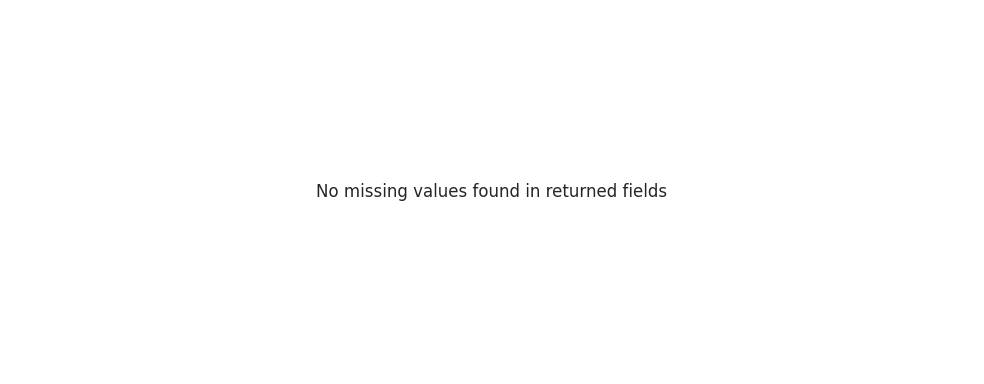

In [7]:
top_missing = missing_summary[missing_summary["missing_count"] > 0].head(20).sort_values("missing_percent")
plt.figure(figsize=(10, max(4, 0.35 * len(top_missing))))
if len(top_missing):
    plt.barh(top_missing["column"], top_missing["missing_percent"])
    plt.xlabel("Missing values (%)")
    plt.ylabel("Metadata field")
    plt.title("GSE282302 metadata completeness: fields with missing values")
else:
    plt.text(0.5, 0.5, "No missing values found in returned fields", ha="center", va="center")
    plt.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "metadata_missingness.png", dpi=160, bbox_inches="tight")
plt.show()


## 6. Basic descriptive statistics
This summarizes the dimensions and annotation coverage of the metadata table. It is not gene-expression statistics.

In [8]:
summary = pd.DataFrame([
    ("GEO series accession", GSE_ID),
    ("Sample records retrieved", len(metadata)),
    ("Metadata fields", len(metadata.columns)),
    ("Exact duplicate rows removed", exact_duplicates_removed),
    ("Duplicate sample accessions remaining", duplicate_accessions),
    ("Total missing cells", int(metadata.isna().sum().sum())),
    ("Overall missing-cell percentage", round(float(metadata.isna().to_numpy().mean() * 100), 2) if metadata.size else 0),
], columns=["metric", "value"])
summary.to_csv(OUT_DIR / "basic_summary_statistics.csv", index=False)
display(summary)


,metric,value
0,GEO series accession,GSE282302
1,Sample records retrieved,108
2,Metadata fields,37
3,Exact duplicate rows removed,0
4,Duplicate sample accessions remaining,0
5,Total missing cells,0
6,Overall missing-cell percentage,0.0


## 7. Inspect sample titles and available annotations
This helps identify the actual metadata fields provided by GEO without assuming that every field exists. Use the printed column names to decide which annotations are meaningful for downstream analysis.

In [9]:
print("Available metadata columns:")
for col in metadata.columns:
    print("-", col)

display(metadata[["sample_accession", "sample_title"]].head(15))


Available metadata columns:
- sample_accession
- sample_title
- status
- submission_date
- last_update_date
- type
- channel_count
- source_name_ch1
- organism_ch1
- taxid_ch1
- characteristics_ch1
- treatment_protocol_ch1
- growth_protocol_ch1
- molecule_ch1
- extract_protocol_ch1
- description
- data_processing
- platform_id
- contact_name
- contact_institute
- contact_address
- contact_city
- contact_state
- contact_zip_postal_code
- contact_country
- instrument_model
- library_selection
- library_source
- library_strategy
- relation
- supplementary_file_1
- supplementary_file_2
- supplementary_file_3
- supplementary_file_4
- supplementary_file_5
- series_id
- data_row_count


,sample_accession,sample_title
0,GSM8641003,C1_D10_ROI1_s1
1,GSM8641004,C1_D10_ROI2_s1
2,GSM8641005,C1_D11_ROI1_s1
3,GSM8641006,C1_D11_ROI2_s1
4,GSM8641007,C1_D12_ROI1_s1
5,GSM8641008,C1_D12_ROI2_s1
6,GSM8641009,C1_D13_ROI1_s1
7,GSM8641010,C1_D13_ROI2_s1
8,GSM8641011,C1_D14_ROI1_s1
9,GSM8641012,C1_D14_ROI2_s1


## 8. Export a quality-control report
The report records what was checked and avoids overstating what metadata QC can establish.

In [10]:
qc_report = {
    "dataset": GSE_ID,
    "official_source": GEO_URL,
    "analysis_scope": "GEO sample metadata only; no full expression-matrix QC",
    "sample_records_retrieved": int(len(metadata)),
    "metadata_columns": int(len(metadata.columns)),
    "exact_duplicate_rows_removed": int(exact_duplicates_removed),
    "duplicate_sample_accessions_remaining": int(duplicate_accessions),
    "total_missing_cells": int(metadata.isna().sum().sum()),
    "overall_missing_cell_percent": round(float(metadata.isna().to_numpy().mean() * 100), 2) if metadata.size else 0,
    "cleaned_metadata_csv": str(DATA_DIR / "GSE282302_sample_metadata_clean.csv"),
    "missingness_csv": str(OUT_DIR / "missing_value_summary.csv"),
    "summary_csv": str(OUT_DIR / "basic_summary_statistics.csv"),
    "interpretation_note": "Missing annotations are reported, not automatically imputed. These checks do not assess gene-expression counts or sequencing quality."
}
with open(OUT_DIR / "quality_control_report.json", "w", encoding="utf-8") as f:
    json.dump(qc_report, f, indent=2)
print(json.dumps(qc_report, indent=2))


{
  "dataset": "GSE282302",
  "official_source": "https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE282302",
  "analysis_scope": "GEO sample metadata only; no full expression-matrix QC",
  "sample_records_retrieved": 108,
  "metadata_columns": 37,
  "exact_duplicate_rows_removed": 0,
  "duplicate_sample_accessions_remaining": 0,
  "total_missing_cells": 0,
  "overall_missing_cell_percent": 0.0,
  "cleaned_metadata_csv": "/content/data/GSE282302_sample_metadata_clean.csv",
  "missingness_csv": "/content/outputs/missing_value_summary.csv",
  "summary_csv": "/content/outputs/basic_summary_statistics.csv",
  "interpretation_note": "Missing annotations are reported, not automatically imputed. These checks do not assess gene-expression counts or sequencing quality."
}


## 9. Interpretation and limitations

- This notebook cleans and summarizes GEO sample metadata, not the underlying gene-expression count matrices.
- Missing metadata values are reported and not imputed because unknown biological annotations should not be guessed.
- Duplicate checks are performed at both the full-row and sample-accession levels.
- A full spatial transcriptomics QC workflow would additionally inspect per-sample H5 matrices, detected genes/features per spot, total counts per spot, mitochondrial/ribosomal fractions where applicable, and spatial coordinates/tissue images.
- The full supplementary archive is approximately 4.9 GB; this notebook avoids downloading it to keep the workflow lightweight.
- Results should be interpreted only after running the notebook and reviewing the generated output files.

## 10. Output files

After successful execution, the notebook creates:

- `data/GSE282302_sample_metadata_clean.csv`
- `outputs/missing_value_summary.csv`
- `outputs/basic_summary_statistics.csv`
- `outputs/metadata_missingness.png`
- `outputs/quality_control_report.json`

**Reproducibility:** run cells from top to bottom in Google Colab. Then download the generated CSV/PNG/JSON files and add them to the repository if required by your reviewer.